In [29]:
import pandas as pd

df = pd.read_pickle("interactions_with_sequences_FINAL_NEW.pkl")


In [30]:
''' TODO Figures Nature-style, pastel nice colors, no default ones, also grey scales are nice..
1. ncRNA interaction type related statistics, types are independent of the order: typea, typeb is equal to typeb, typea. 1.2 Also Based on species.
2. Transcripts-per-entity: 2.2 Also based on type and species. use # seq1_list, seq2_list columns
3. Species related statistics. 3.2 Also based on ncRNAtype.
4. Sequence length related statistics. 4.2 Also Takig transcripts into account.
5. GO/RFAM IDs statistics based on species 5.1 /ncRNAtype 5.2

Start with what i did. the dataframe is df.
Use large fonts, and figures ready for nat comm.
'''

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy.stats import entropy

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (6,4)

print("Shape:", df.shape)
df.head()


df["type_pair_unordered"] = df.apply(
    lambda x: tuple(sorted([x["Category1"], x["Category2"]])),
    axis=1
)

type_pair_counts = df["type_pair_unordered"].value_counts()

type_pair_counts.head(40)


df["species_pair_unordered"] = df.apply(
    lambda x: tuple(sorted([x["Species1"], x["Species2"]])),
    axis=1
)

species_pair_counts = df["species_pair_unordered"].value_counts()
species_pair_counts.head(40)



Shape: (82171, 31)


,RNAInterID,Interactor1.Symbol,Category1,Species1,Interactor2.Symbol,Category2,Species2,Raw_ID1,Raw_ID2,score,...,key1,key2,seq1_list,GO1,Rfam1,ID_buckets1,seq2_list,GO2,Rfam2,ID_buckets2
0,RR00887844,hsa-miR-101-3p,miRNA,Homo sapiens,MALAT1,lncRNA,Homo sapiens,miRBase:MIMAT0000099,NCBI:378938,0.7494,...,"(hsa-miR-101-3p, miRNA, 9606, (miRBase:MIMAT00...","(MALAT1, lncRNA, 9606, (NCBI:378938,))",[UACAGUACUGUGAUAACUGAA],[<NA>],[<NA>],"{'miRBase': ['MIMAT0000099'], 'NCBI': [], 'Ens...",[CGCAGCCUGCAGCCCGAGACUUCUGUAAAGGACUGGGGCCCCGCA...,[GO:2000147],"[RF01684, RF01871]","{'miRBase': [], 'NCBI': ['378938'], 'Ensembl':..."
1,RR00990499,hsa-miR-101-3p,miRNA,Homo sapiens,NEAT1,lncRNA,Homo sapiens,miRBase:MIMAT0000099,NCBI:283131,0.6993,...,"(hsa-miR-101-3p, miRNA, 9606, (miRBase:MIMAT00...","(NEAT1, lncRNA, 9606, (NCBI:283131,))",[UACAGUACUGUGAUAACUGAA],[<NA>],[<NA>],"{'miRBase': ['MIMAT0000099'], 'NCBI': [], 'Ens...",[GGAGUUAGCGACAGGGAGGGAUGCGCGCCUGGGUGUAGUUGUGGG...,"[GO:0016442, GO:0005515, GO:0035195, GO:0042382]","[RF01955, RF01957, RF00959, RF01956]","{'miRBase': [], 'NCBI': ['283131'], 'Ensembl':..."
2,RR00889491,hsa-miR-129-5p,miRNA,Homo sapiens,MALAT1,lncRNA,Homo sapiens,miRBase:MIMAT0000242,NCBI:378938,0.6338,...,"(hsa-miR-129-5p, miRNA, 9606, (miRBase:MIMAT00...","(MALAT1, lncRNA, 9606, (NCBI:378938,))",[CUUUUUGCGGUCUGGGCUUGC],[<NA>],[<NA>],"{'miRBase': ['MIMAT0000242'], 'NCBI': [], 'Ens...",[CGCAGCCUGCAGCCCGAGACUUCUGUAAAGGACUGGGGCCCCGCA...,[GO:2000147],"[RF01684, RF01871]","{'miRBase': [], 'NCBI': ['378938'], 'Ensembl':..."
3,RR00719414,hsa-miR-130a-3p,miRNA,Homo sapiens,HOTAIR,lncRNA,Homo sapiens,miRBase:MIMAT0000425,NCBI:100124700,0.4481,...,"(hsa-miR-130a-3p, miRNA, 9606, (miRBase:MIMAT0...","(HOTAIR, lncRNA, 9606, (NCBI:100124700,))",[CAGUGCAAUGUUAAAAGGGCAU],[<NA>],[<NA>],"{'miRBase': ['MIMAT0000425'], 'NCBI': [], 'Ens...",[GCCUGUGCUCUGGAGCUUGAUCCGAAAGCUUCCACAGUGAGGACU...,"[GO:0005515, GO:0031507]","[RF01905, RF01904, RF01906]","{'miRBase': [], 'NCBI': ['100124700'], 'Ensemb..."
4,RR01560384,hsa-miR-137-3p,miRNA,Homo sapiens,XIST,lncRNA,Homo sapiens,miRBase:MIMAT0000429,NCBI:7503,0.6165,...,"(hsa-miR-137-3p, miRNA, 9606, (miRBase:MIMAT00...","(XIST, lncRNA, 9606, (NCBI:7503,))",[UUAUUGCUUAAGAAUACGCGUAG],[<NA>],[<NA>],"{'miRBase': ['MIMAT0000429'], 'NCBI': [], 'Ens...",[AUAUUUCUUACUCUCUCGGGGCUGGAAGCUUCCUGACUGAAGAUC...,"[GO:0009048, GO:0016458]","[RF02266, RF01880, RF02162, RF01881]","{'miRBase': [], 'NCBI': ['7503'], 'Ensembl': [..."


In [45]:
df.keys()

Index(['RNAInterID', 'Interactor1.Symbol', 'Category1', 'Species1',
       'Interactor2.Symbol', 'Category2', 'Species2', 'Raw_ID1', 'Raw_ID2',
       'score', 'strong', 'weak', 'predict', 'Raw_ID1_list', 'Raw_ID2_list',
       'Species1_TaxID', 'Species2_TaxID', 'Category1_std', 'Category2_std',
       'Raw_ID1_key', 'Raw_ID2_key', 'key1', 'key2', 'seq1_list', 'GO1',
       'Rfam1', 'ID_buckets1', 'seq2_list', 'GO2', 'Rfam2', 'ID_buckets2',
       'type_pair_unordered', 'species_pair_unordered', 'n_transcripts_1',
       'n_transcripts_2', 'n_transcripts_total'],
      dtype='object')

Final dataset size: 81847
Types retained: 13
Species pairs retained: 27


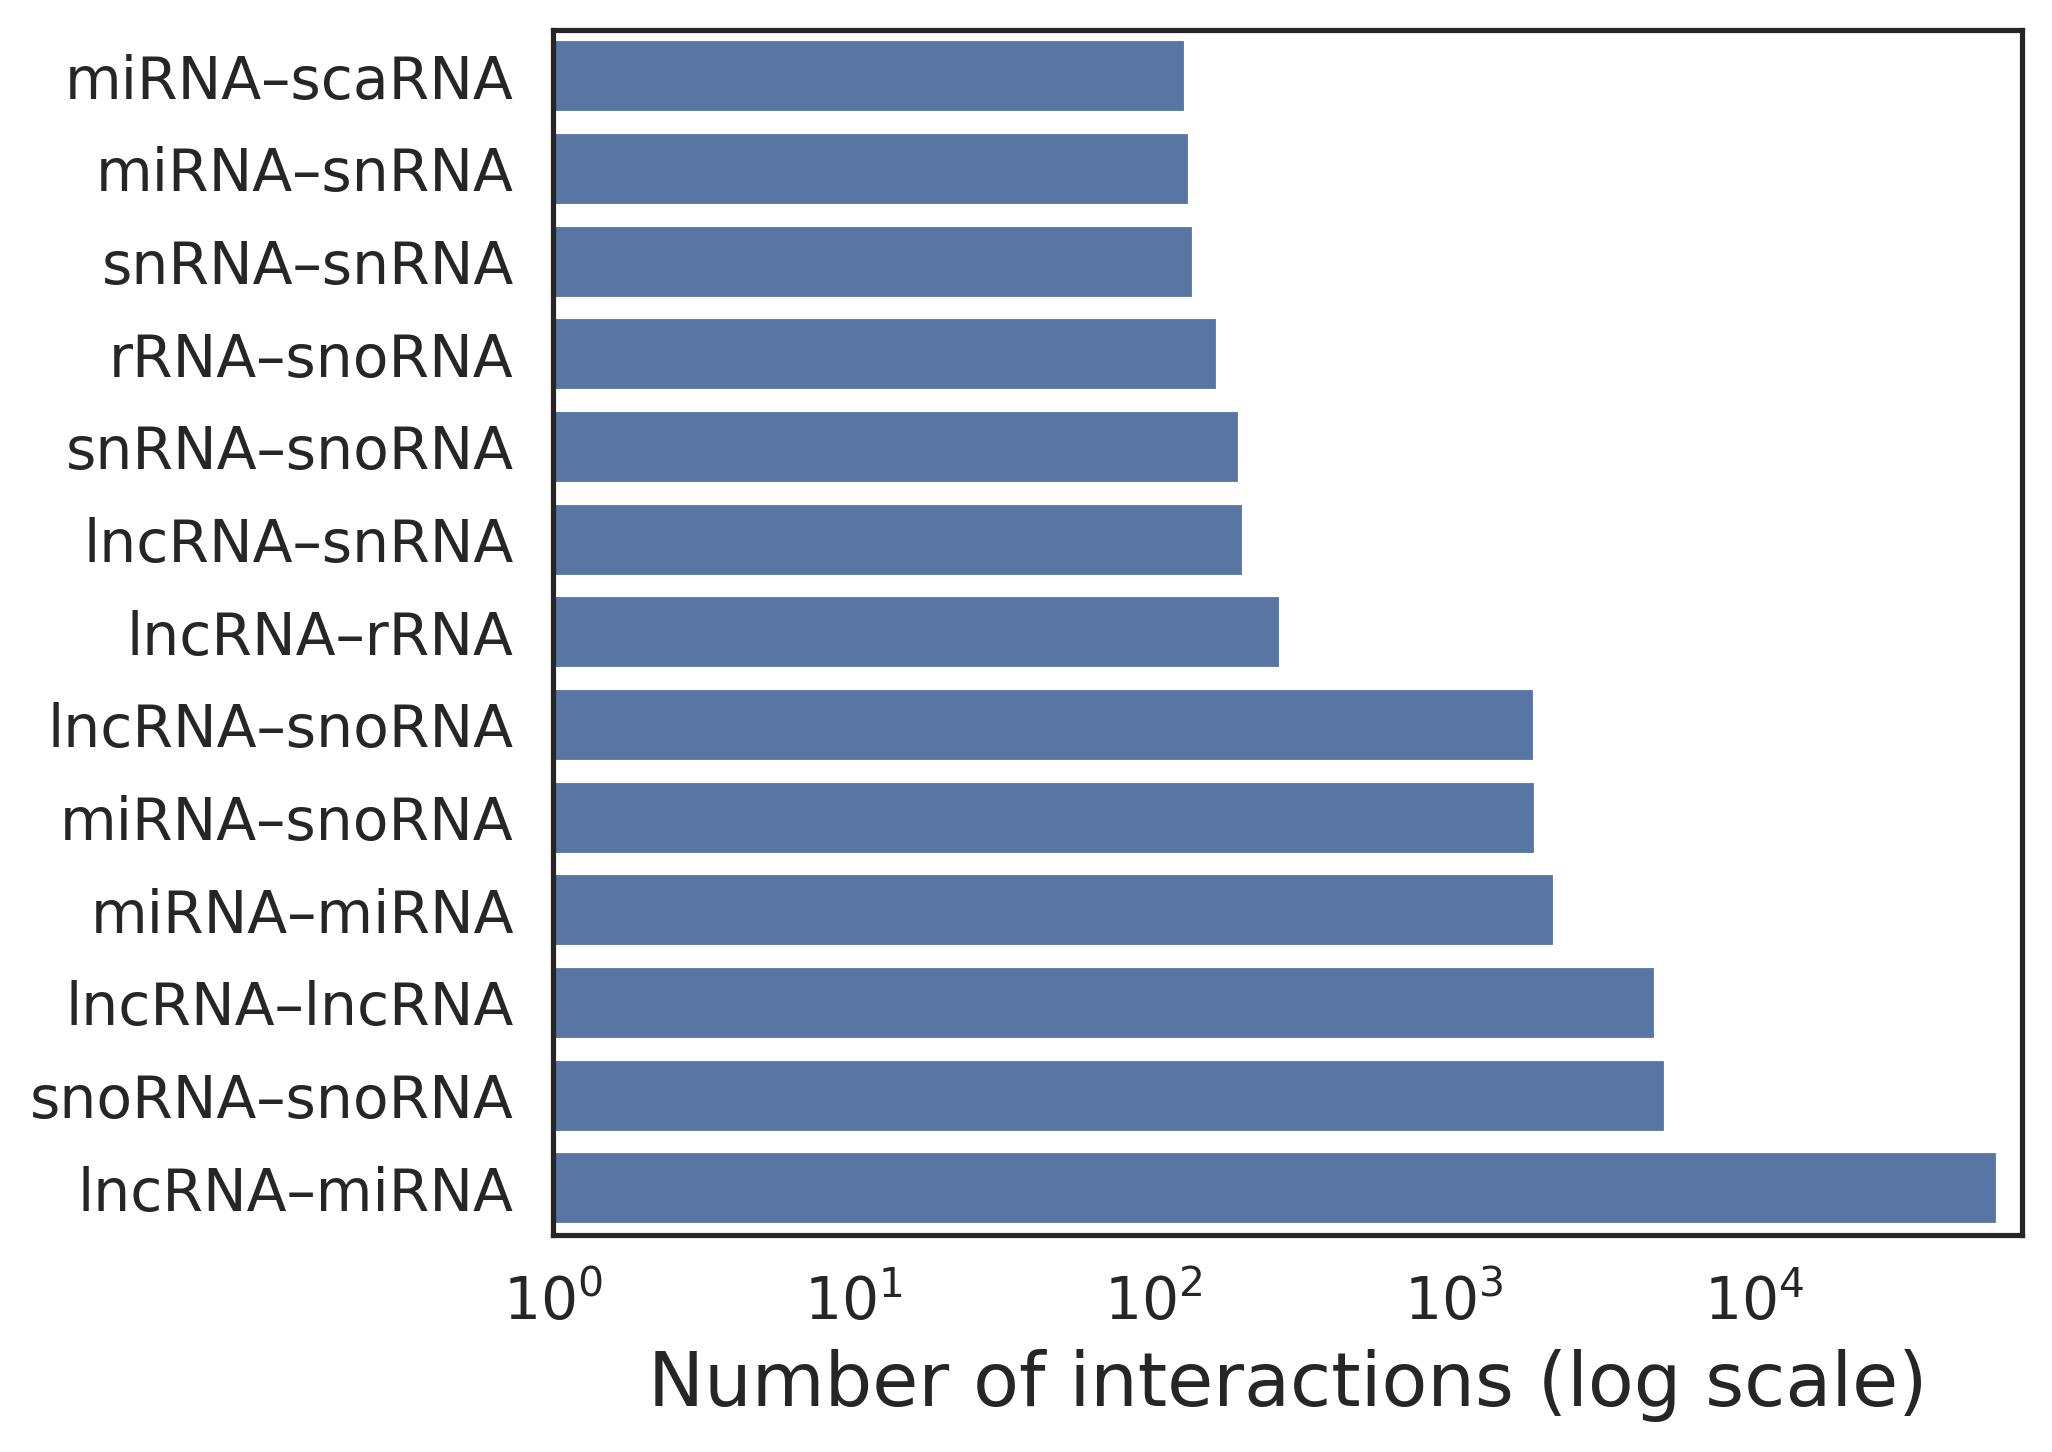

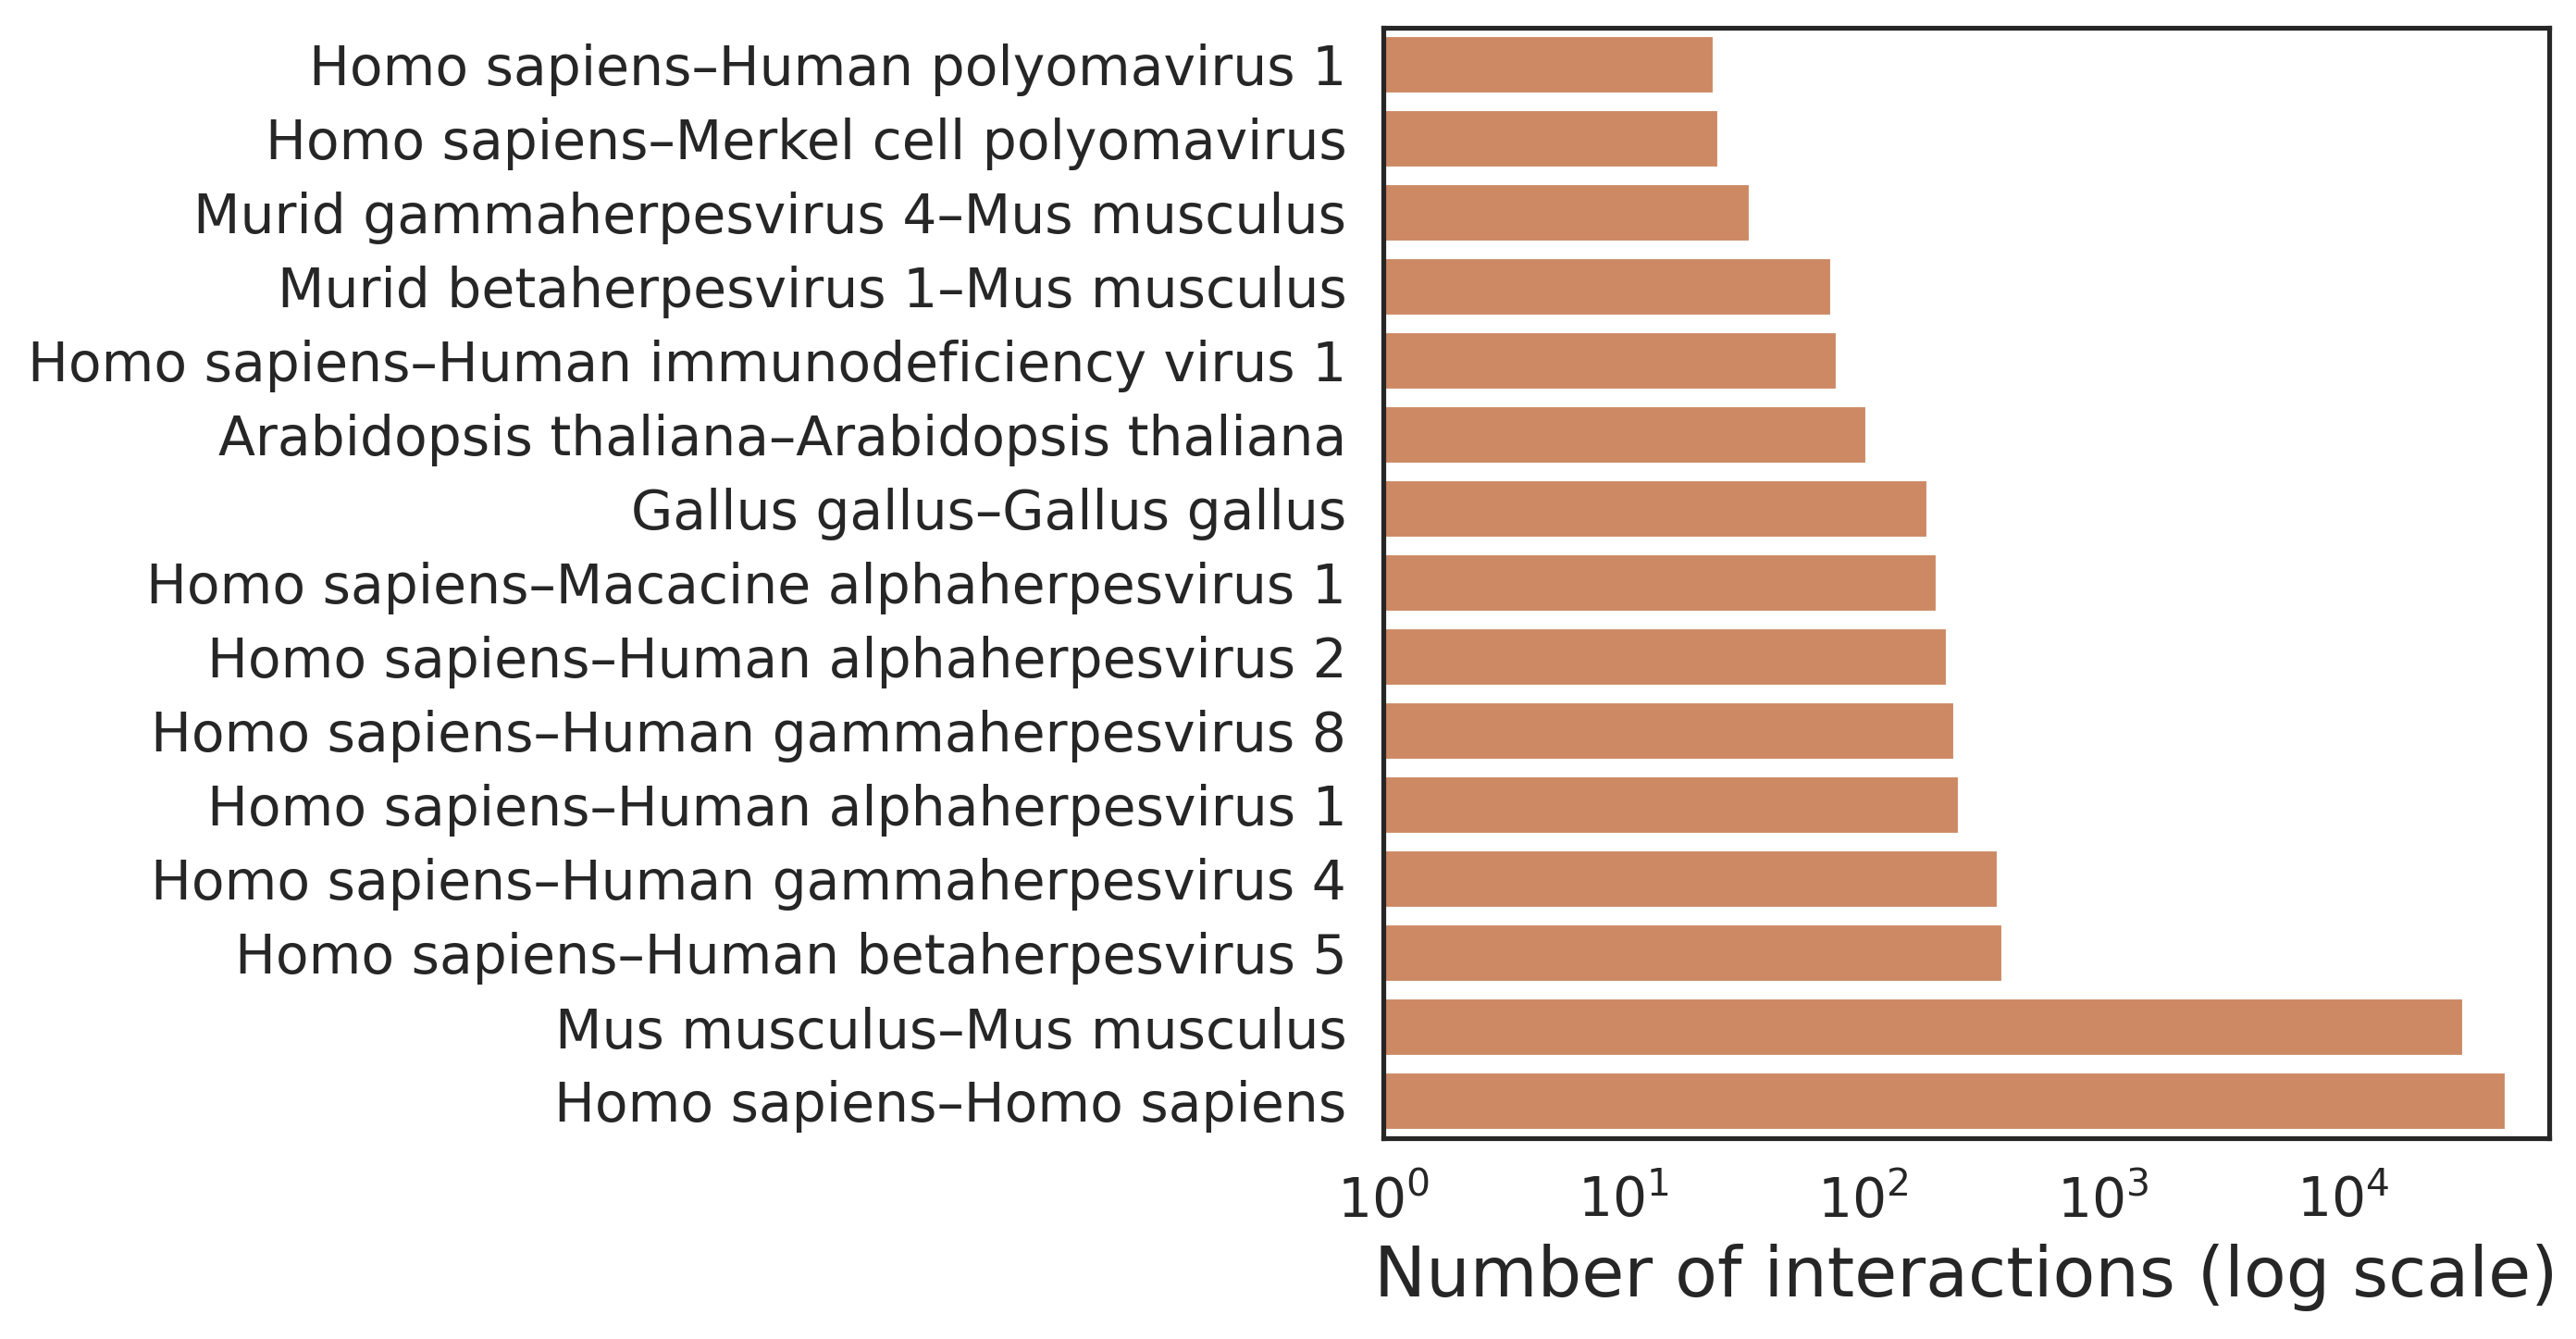

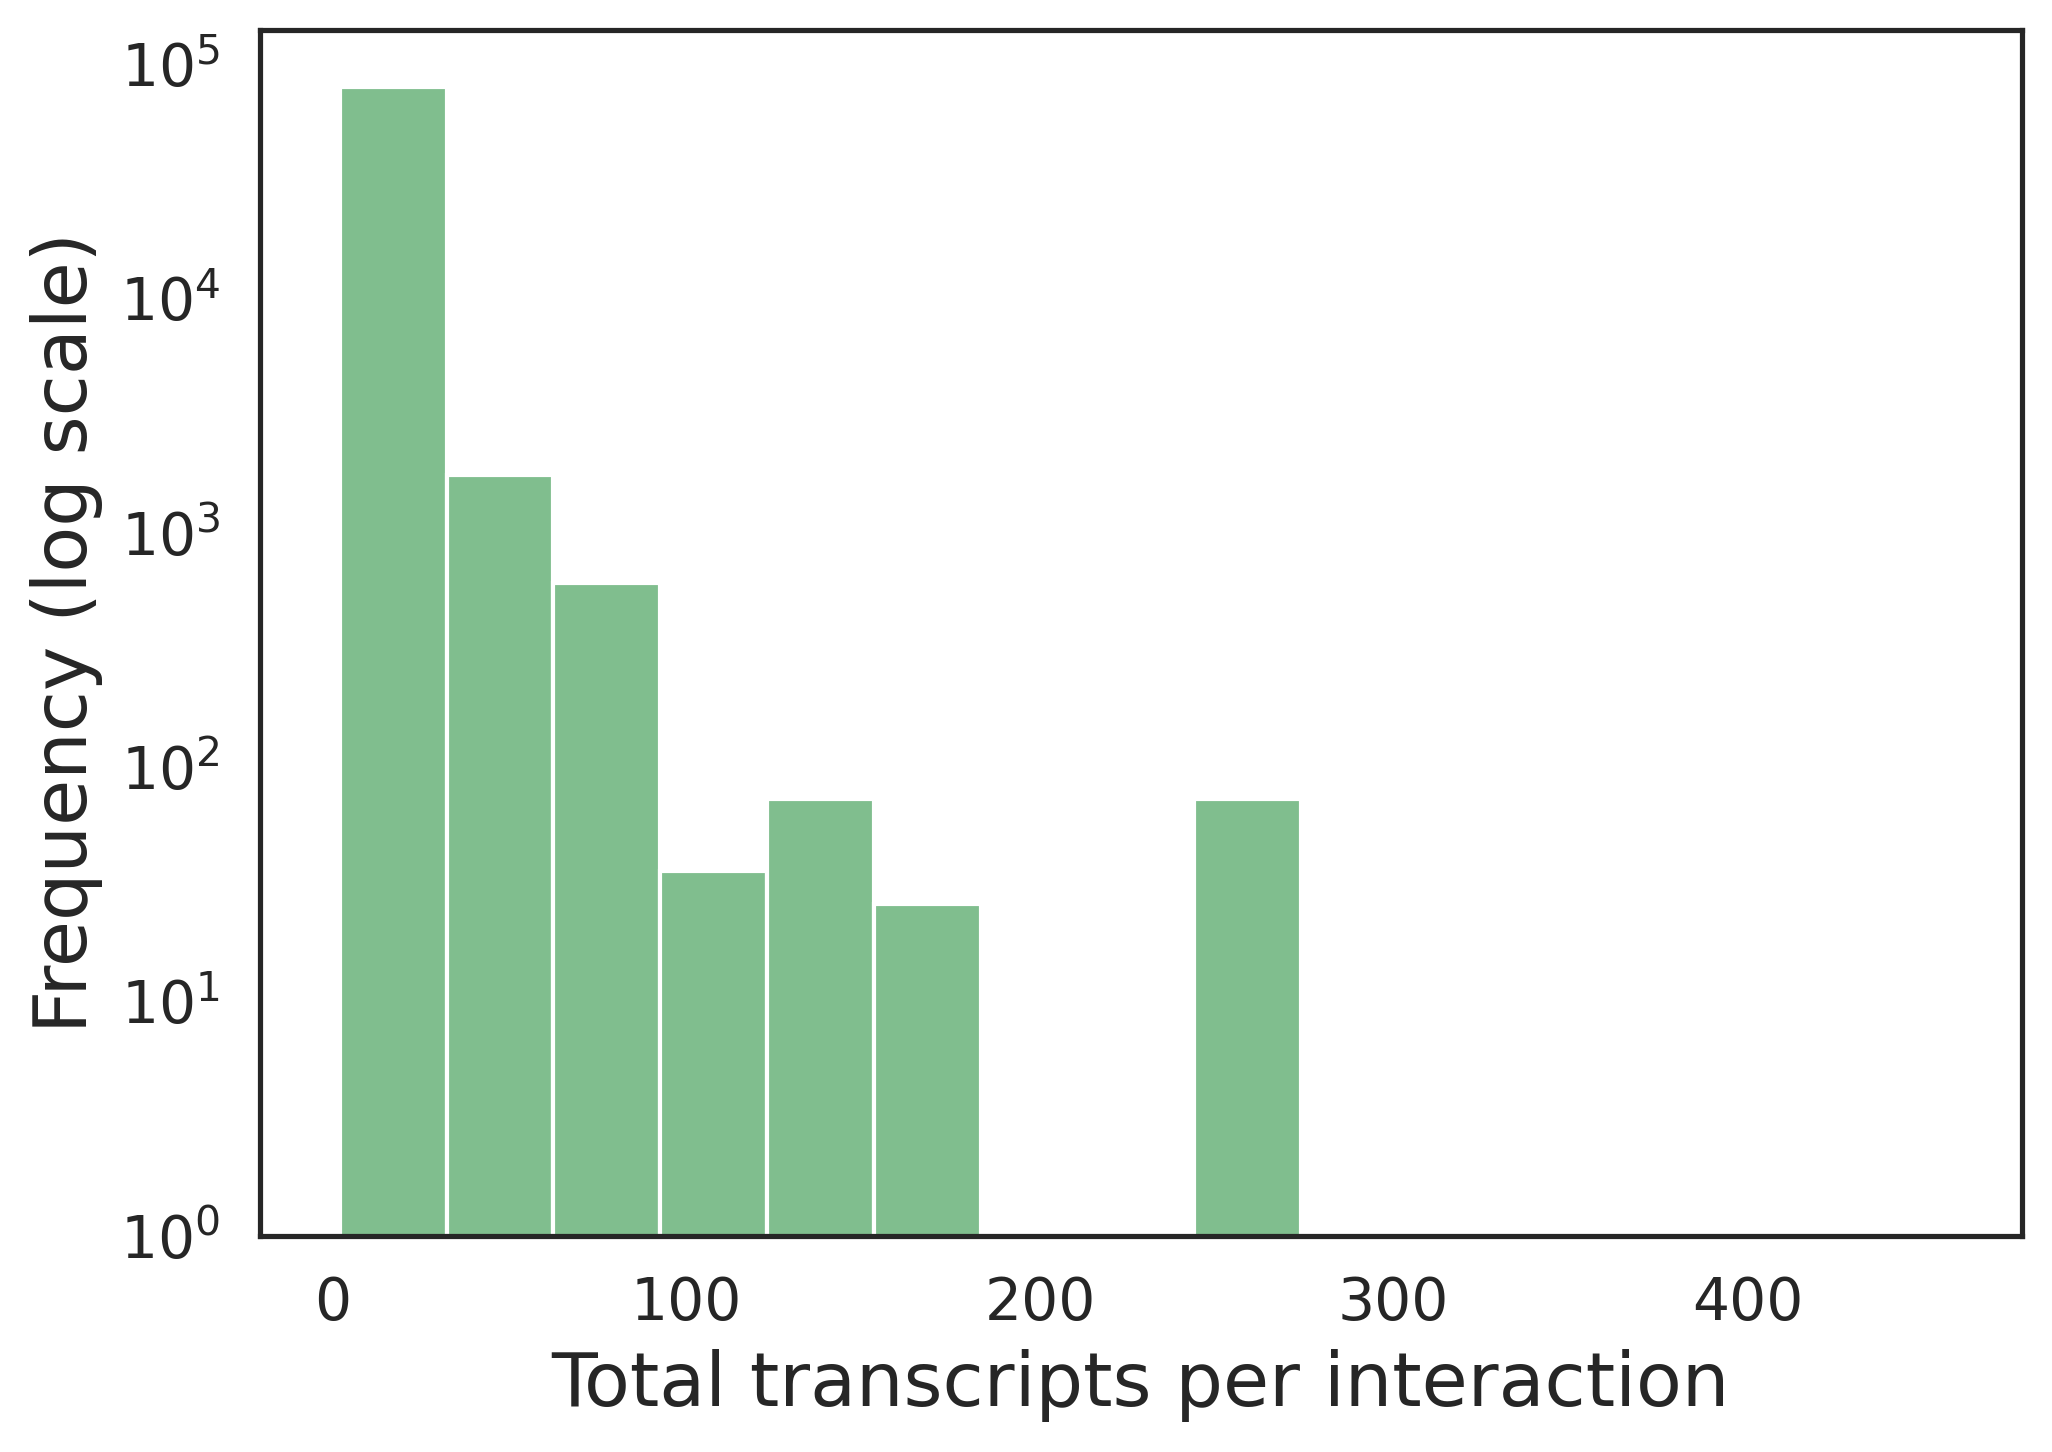

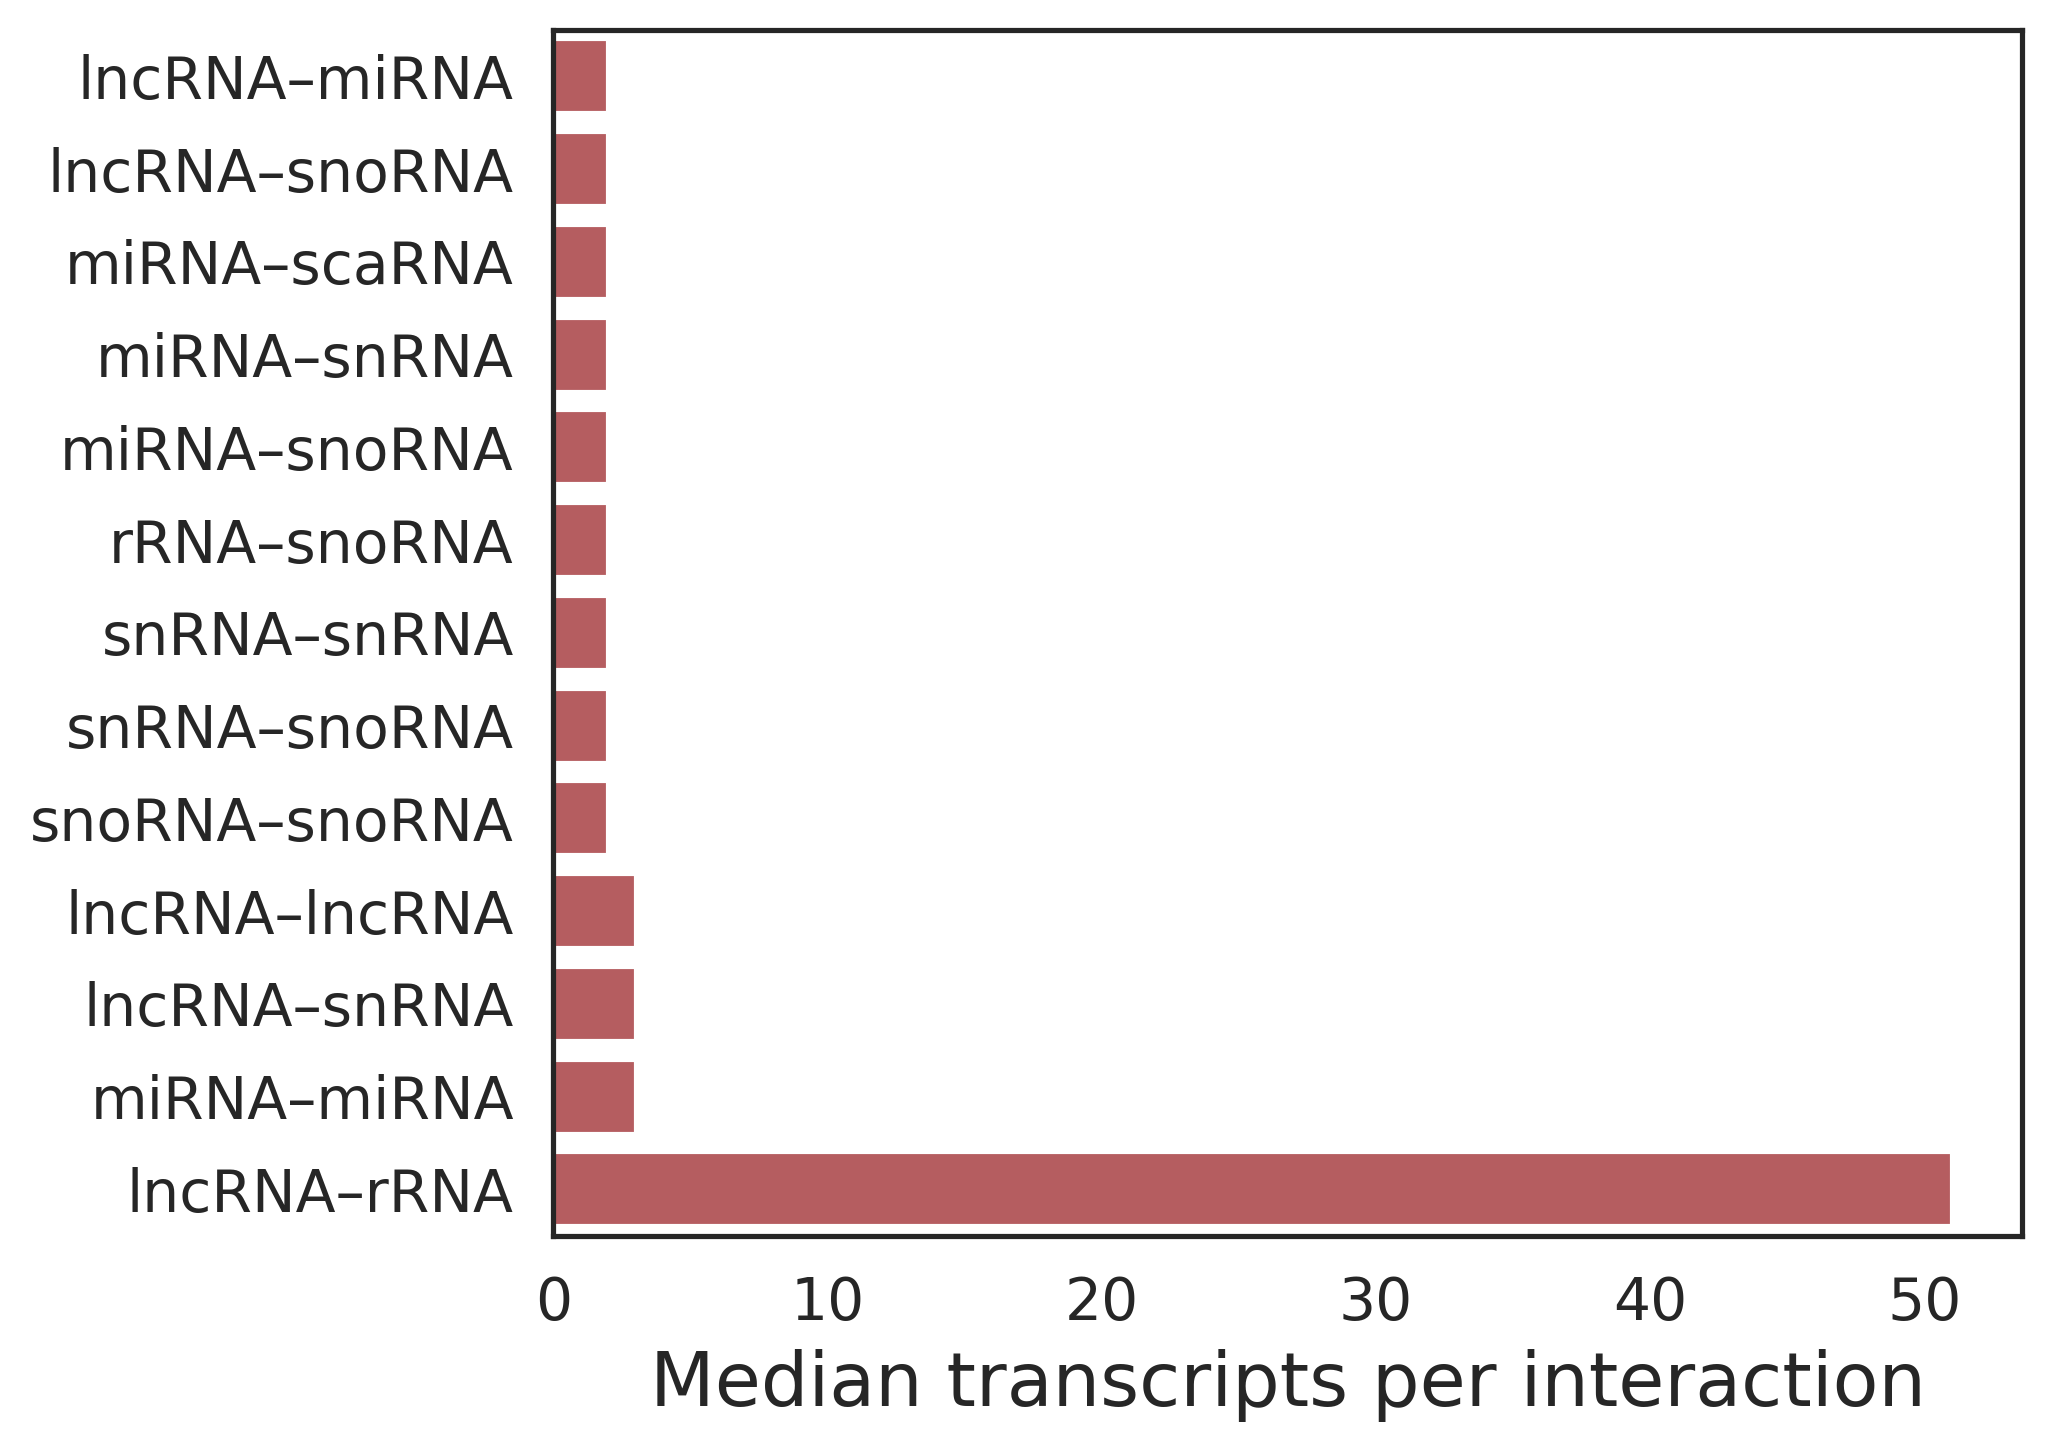

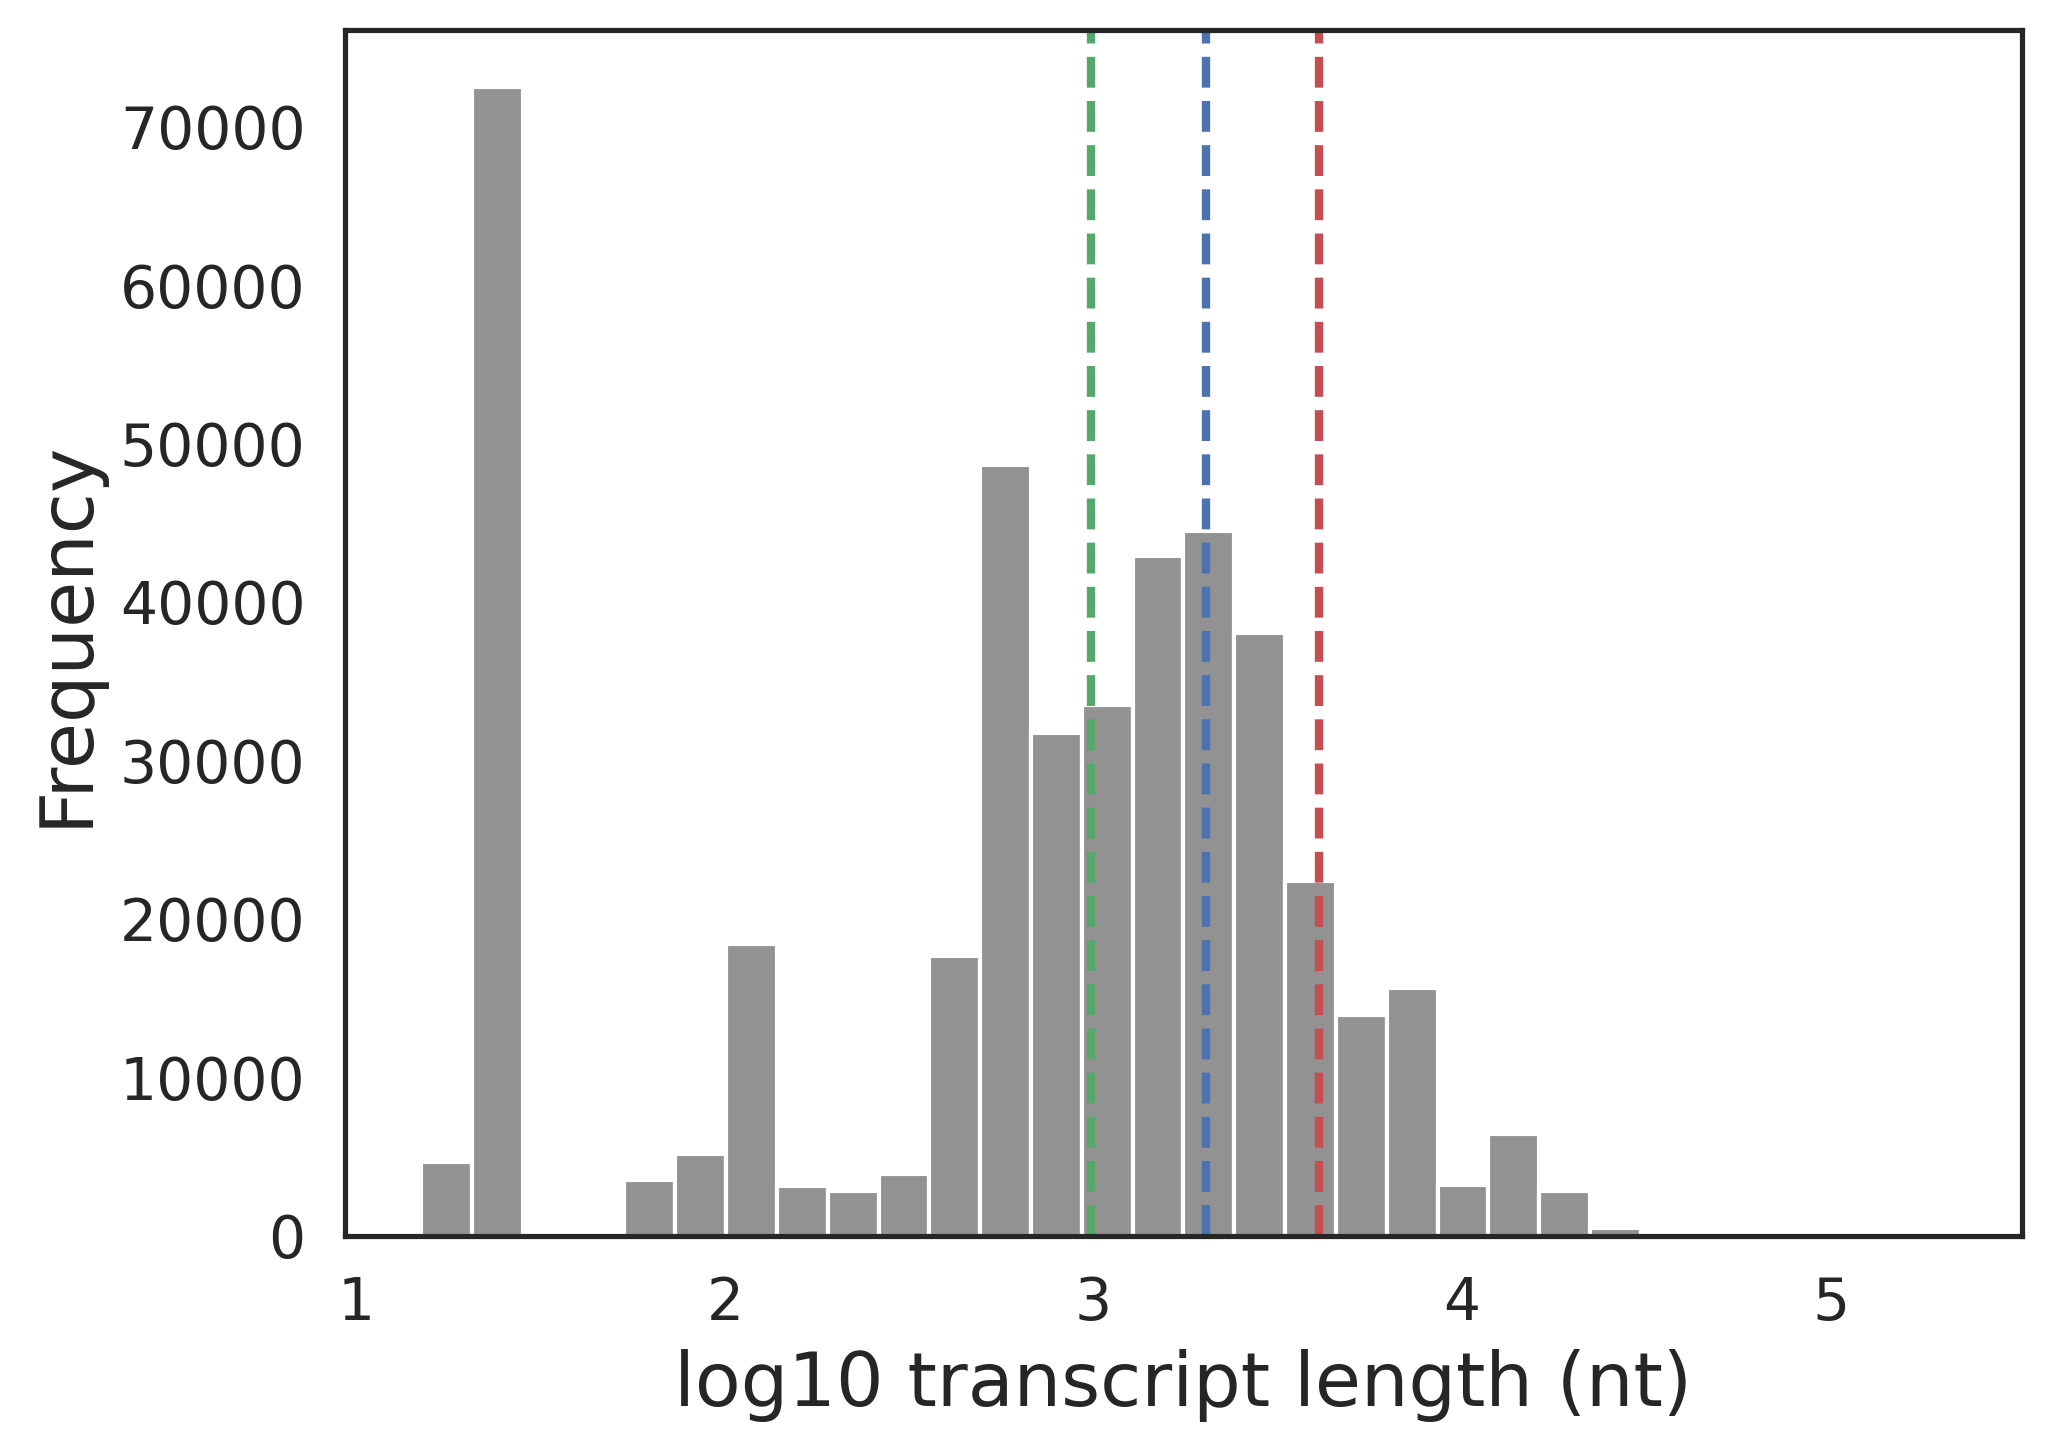

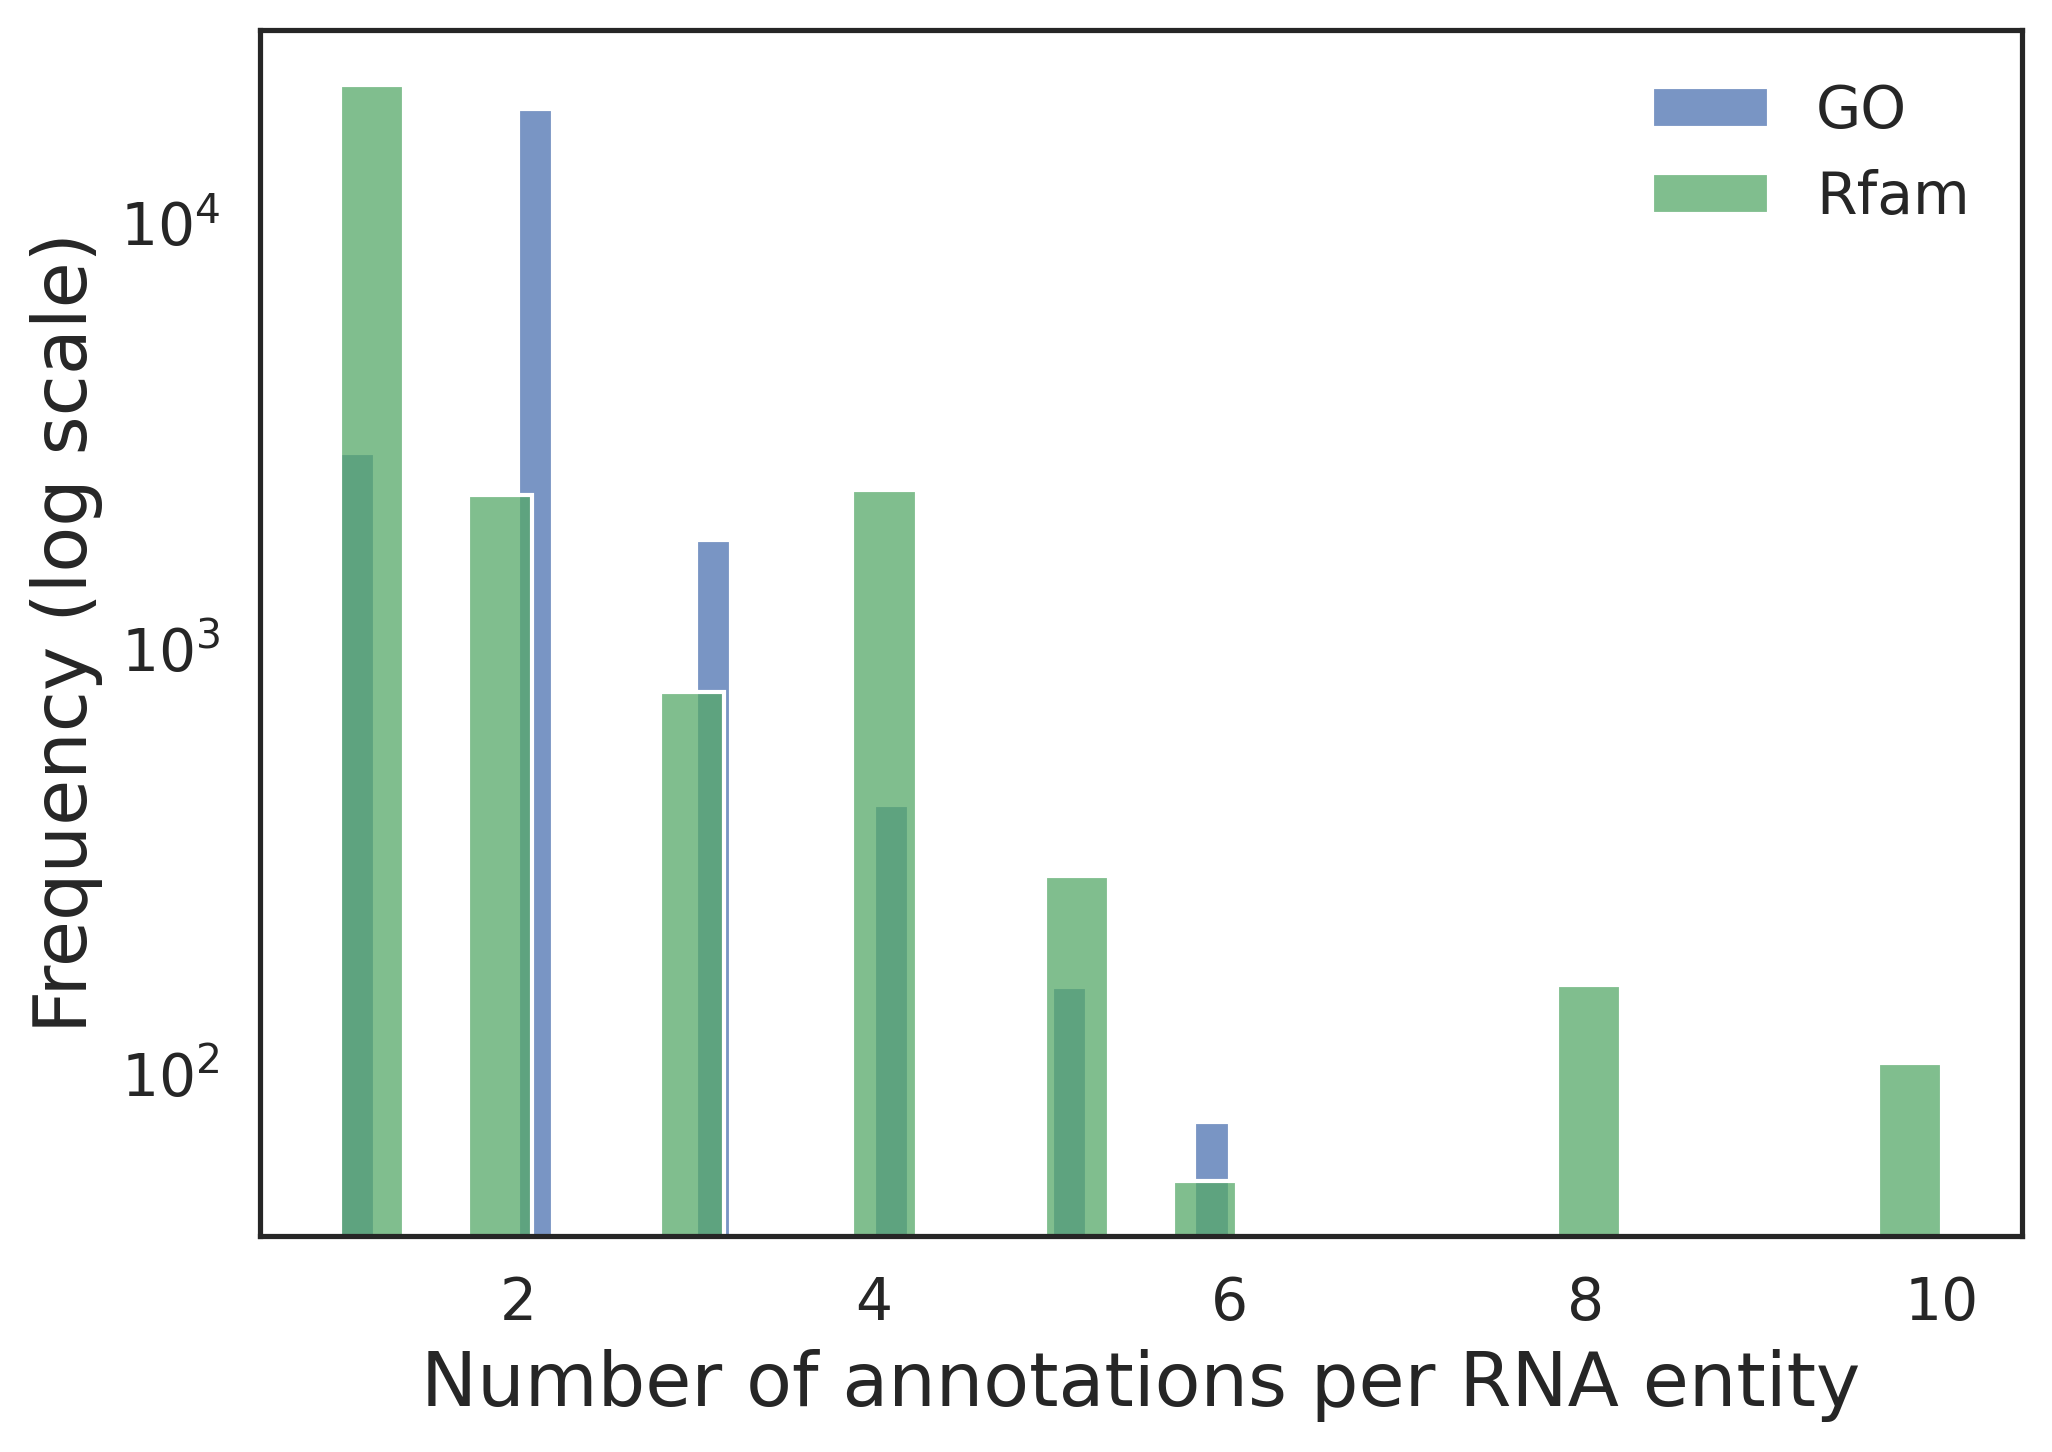

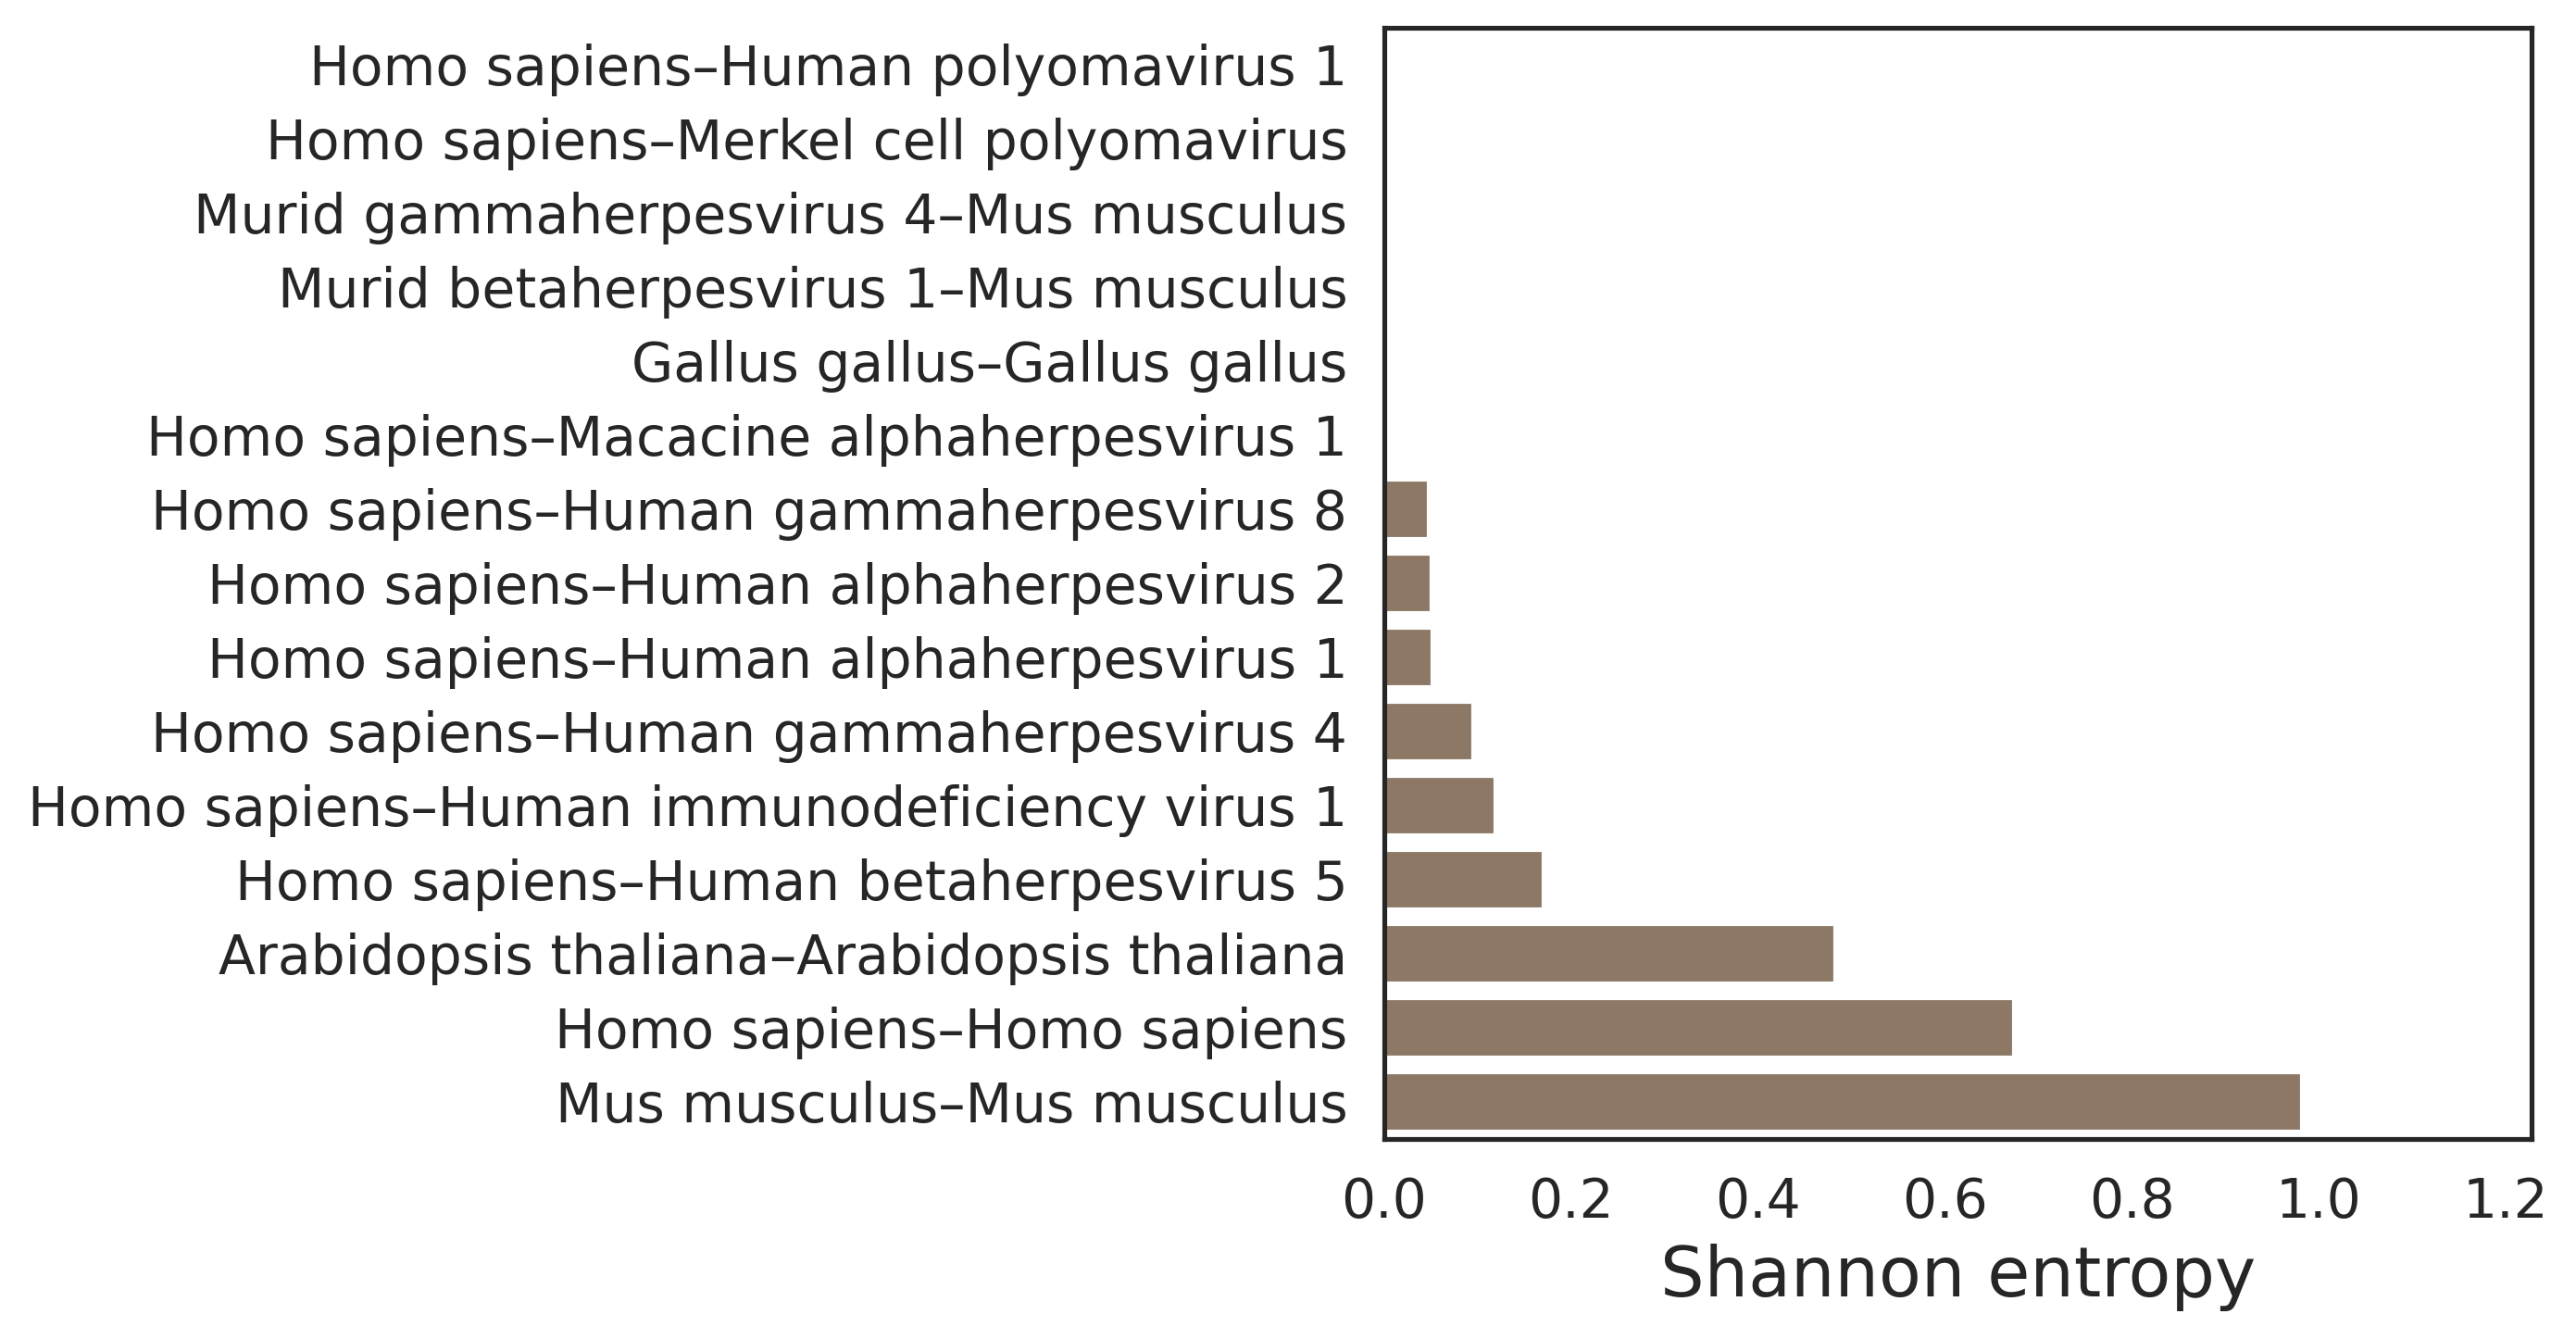

All figures saved as PDF.


In [68]:
# ==========================================
# RNA Interaction Dataset – Core Landscape
# Clean, reduced, publication-ready
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from scipy.stats import entropy

# ---------------------------
# Global style
# ---------------------------
mpl.rcParams.update({
    "figure.figsize": (7,5),
    "figure.dpi": 300,
    "axes.labelsize": 18,
    "axes.titlesize": 20,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "sans-serif"
})

sns.set_style("white")

COLOR_TYPE = "#4C72B0"
COLOR_SPECIES = "#DD8452"
COLOR_TRANSCRIPT = "#55A868"
COLOR_LENGTH = "#6E6E6E"
COLOR_ANNOT = "#8172B3"
COLOR_ENTROPY = "#937860"

# ============================================================
# 1. Filtering
# ============================================================

type_counts = df["type_pair_unordered"].value_counts()
valid_types = type_counts[type_counts >= 100].index
df_f = df[df["type_pair_unordered"].isin(valid_types)].copy()

print("Final dataset size:", len(df_f))
print("Types retained:", df_f["type_pair_unordered"].nunique())
print("Species pairs retained:", df_f["species_pair_unordered"].nunique())

# ============================================================
# 2. Interaction Type Distribution (log scale)
# ============================================================

type_counts_f = df_f["type_pair_unordered"].value_counts().sort_values()

plt.figure()
sns.barplot(
    x=type_counts_f.values,
    y=[f"{a}–{b}" for a,b in type_counts_f.index],
    color=COLOR_TYPE
)
plt.xscale("log")
plt.xlim(1, type_counts_f.values.max() * 1.2)
plt.xlabel("Number of interactions (log scale)")
plt.tight_layout()
plt.savefig("Fig1_type_distribution.pdf")
plt.show()
plt.close()

# ============================================================
# 3. Species Interaction Landscape (Top 15)
# ============================================================

species_counts_f = (
    df_f["species_pair_unordered"]
    .value_counts()
    .head(15)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(7,5))

sns.barplot(
    x=species_counts_f.values,
    y=[f"{a}–{b}" for a,b in species_counts_f.index],
    color=COLOR_SPECIES,
    ax=ax
)

ax.set_xscale("log")

# add proper right margin buffer
max_val = species_counts_f.values.max()
ax.set_xlim(1, max_val * 1.5)

ax.set_xlabel("Number of interactions (log scale)")

# manually adjust margins (prevents right cutoff)
fig.subplots_adjust(left=0.35, right=0.95, top=0.95, bottom=0.15)

plt.savefig("Fig2_species_landscape.pdf", bbox_inches="tight")
plt.show()
plt.close()


# ============================================================
# 4. Transcript Multiplicity
# ============================================================

plt.figure()
sns.histplot(
    df_f["n_transcripts_total"],
    bins=15,
    color=COLOR_TRANSCRIPT
)
plt.yscale("log")
plt.ylim(bottom=1)
plt.xlabel("Total transcripts per interaction")
plt.ylabel("Frequency (log scale)")
plt.tight_layout()
plt.savefig("Fig3_transcript_multiplicity.pdf")
plt.show()
plt.close()

# Median transcript multiplicity per type
transcript_median = (
    df_f.groupby("type_pair_unordered")["n_transcripts_total"]
    .median()
    .sort_values()
)

plt.figure()
sns.barplot(
    x=transcript_median.values,
    y=[f"{a}–{b}" for a,b in transcript_median.index],
    color="#C44E52"
)
plt.xlabel("Median transcripts per interaction")
plt.tight_layout()
plt.savefig("Fig3b_transcript_median_per_type.pdf")
plt.show()
plt.close()

# ============================================================
# 5. Transcript Length Distribution (log-scale)
# ============================================================

all_lengths = []

for lst in df_f["seq1_list"]:
    if isinstance(lst, list):
        all_lengths.extend([len(s) for s in lst if isinstance(s, str)])

for lst in df_f["seq2_list"]:
    if isinstance(lst, list):
        all_lengths.extend([len(s) for s in lst if isinstance(s, str)])

all_lengths = np.array(all_lengths)
all_lengths = all_lengths[all_lengths > 0]

mean_len = np.mean(all_lengths)
median_len = np.median(all_lengths)

plt.figure()
sns.histplot(
    np.log10(all_lengths),
    bins=30,
    color=COLOR_LENGTH
)

plt.axvline(np.log10(4096), color="#C44E52", linestyle="--", linewidth=2)
plt.axvline(np.log10(mean_len), color="#4C72B0", linestyle="--", linewidth=2)
plt.axvline(np.log10(median_len), color="#55A868", linestyle="--", linewidth=2)

plt.xlabel("log10 transcript length (nt)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("Fig4_transcript_length_log_distribution.pdf")
plt.show()
plt.close()

# ============================================================
# 6. Functional Annotation Landscape (Entity-Level)
# ============================================================

def count_valid_annotations(x):
    if isinstance(x, list):
        return len([v for v in x if pd.notna(v)])
    return 0

df_f["n_GO1"] = df_f["GO1"].apply(count_valid_annotations)
df_f["n_GO2"] = df_f["GO2"].apply(count_valid_annotations)
df_f["n_Rfam1"] = df_f["Rfam1"].apply(count_valid_annotations)
df_f["n_Rfam2"] = df_f["Rfam2"].apply(count_valid_annotations)

all_GO = pd.concat([df_f["n_GO1"], df_f["n_GO2"]])
all_Rfam = pd.concat([df_f["n_Rfam1"], df_f["n_Rfam2"]])

# Annotation depth (log scale)
plt.figure()
sns.histplot(all_GO[all_GO > 0], bins=25, color="#4C72B0", label="GO")
sns.histplot(all_Rfam[all_Rfam > 0], bins=25, color="#55A868", label="Rfam")
plt.yscale("log")
plt.xlabel("Number of annotations per RNA entity")
plt.ylabel("Frequency (log scale)")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("Fig6_annotation_depth.pdf")
plt.show()
plt.close()

# ============================================================
# 7. Interaction-Type Diversity per Species
# ============================================================

entropy_values = []
species_list = species_counts_f.index

for sp in species_list:
    subset = df_f[df_f["species_pair_unordered"] == sp]
    counts = subset["type_pair_unordered"].value_counts()
    entropy_values.append(entropy(counts))

entropy_series = pd.Series(
    entropy_values,
    index=[f"{a}–{b}" for a,b in species_list]
).sort_values()

fig, ax = plt.subplots(figsize=(7,5))

sns.barplot(
    x=entropy_series.values,
    y=entropy_series.index,
    color=COLOR_ENTROPY,
    ax=ax
)

max_val = entropy_series.max()
ax.set_xlim(0, max_val * 1.25)  # more right padding
ax.set_xlabel("Shannon entropy")
ax.set_ylabel("")

# manual margin control (critical for NatComm-style large fonts)
fig.subplots_adjust(left=0.38, right=0.97, top=0.95, bottom=0.15)

plt.savefig("Fig7_species_entropy.pdf", bbox_inches="tight")
plt.show()
plt.close()


print("All figures saved as PDF.")
